# Klasifikasi Kesegaran Daging dengan SVM (Fresh / Half-Fresh / Spoiled)

Notebook ini membangun model **Support Vector Machine (SVM)** untuk mengklasifikasikan citra daging ke tiga kelas: FRESH, HALF-FRESH, dan SPOILED, memakai *Meat Freshness Image Dataset* dari Kaggle (2.266 citra).

**Alur:** download data → cek data → preprocessing → augmentasi → segmentasi → visualisasi histogram & tekstur → ekstraksi fitur (dua set) → tuning → evaluasi → uji ketahanan cahaya → uji foto lapangan → simpan model.

**Rancangan:**
- **Preprocessing**: resize 224×224, normalisasi piksel 0–1.
- **Augmentasi** (hanya data train): geometri (rotasi, geser, zoom, flip) dan **cahaya/warna** (brightness, suhu warna, gamma).
- **Segmentasi**: daging dipisahkan dari latar dengan ambang warna HSV setelah koreksi warna cahaya, lalu pembersihan morfologi.
- **Dua set fitur** dibandingkan: *Dasar* (RGB+HSV+LBP) dan *Lanjutan* (warna Lab, tekstur multi-skala, dll.).
- **Pemilihan model** memakai cross-validation pada data train, bukan data test.
- **Evaluasi** pada data test, ditambah uji ketahanan terhadap perubahan cahaya.

## 1. Import library dan konfigurasi

Sel ini memuat library dan menetapkan konfigurasi:
- `IMG_SIZE`: ukuran citra 224×224
- `N_AUG`: jumlah salinan augmentasi per gambar train (0 = tanpa augmentasi)
- `AUG`: rentang augmentasi geometri dan cahaya/warna
- `SHIFT_NAMES`: variasi cahaya tetap untuk uji ketahanan (hanya dipakai saat evaluasi)
- `C_GRID`, `GAMMA_MULT`: kandidat parameter SVM yang dicoba saat tuning
- `SEED = 42`: agar hasil bisa diulang

In [ ]:
import os, random, warnings, json
import numpy as np, pandas as pd, cv2, joblib
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.stats import skew
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from IPython.display import display
from skimage.feature import local_binary_pattern
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

CLASS_NAMES  = ["FRESH", "HALF-FRESH", "SPOILED"]
CLASS_COLORS = ["#2e9e4f", "#e6a700", "#c0392b"]

# ---- Preprocessing ----
IMG_SIZE = (224, 224)
N_AUG    = 2          # jumlah salinan augmentasi per gambar TRAIN (0 = tanpa augmentasi)
AUG = dict(rotation=20, shift=0.10, zoom=0.20, flip=True,       # augmentasi geometri
           brightness=(0.6, 1.4), color_shift=0.15, gamma=(0.8, 1.25))   # augmentasi cahaya & warna

# ---- Uji ketahanan cahaya (khusus evaluasi, tidak dipakai saat training) ----
SHIFT_NAMES = ["terang", "gelap", "hangat", "dingin"]

# ---- Tuning SVM ----
N_SPLITS = 3
C_GRID, GAMMA_MULT = [1, 10, 100], [0.3, 1, 3]      # gamma = pengali / jumlah_fitur

## 2. Download dataset dari Kaggle

Upload `kaggle.json` (Kaggle → Settings → API → Create New Token). Dataset lalu diunduh dan diekstrak ke folder `meat_dataset`.

In [ ]:
from google.colab import files

print("Upload file kaggle.json")
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d vinayakshanawad/meat-freshness-image-dataset
!rm -rf meat_dataset
!unzip -q -o meat-freshness-image-dataset.zip -d meat_dataset

Upload file kaggle.json


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/vinayakshanawad/meat-freshness-image-dataset
License(s): CC0-1.0
100% 59.4M/59.4M [00:00<00:00, 192MB/s]



## 3. Membaca daftar file dan label

Dataset ini **tidak punya subfolder per kelas**. Label menempel di awal nama file (`FRESH-...`, `HALF-FRESH-...`, `SPOILED-...`). Sel ini membuat tabel path dan label, lalu menampilkan jumlah gambar per kelas.

Pembagian data mengikuti bawaan dataset (sekitar 80:20): folder `train` menjadi **data train**, folder `valid` menjadi **data test**. Label: 0 = FRESH, 1 = HALF-FRESH, 2 = SPOILED.

Total train: 1815 | Total test: 451


,train,test
FRESH,675,178
HALF-FRESH,630,159
SPOILED,510,114


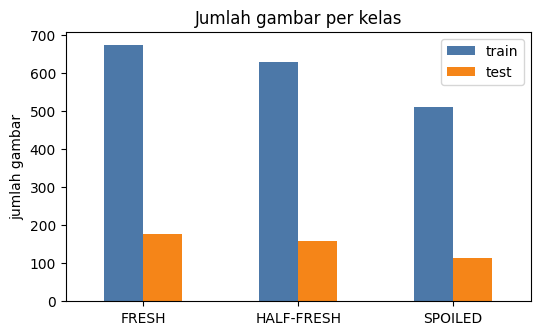

In [ ]:
def find_split_dir(root, name):
    for r, dirs, fs in os.walk(root):
        if os.path.basename(r) == name and any(f.lower().endswith(".jpg") for f in fs):
            return r
    raise FileNotFoundError(f"Folder '{name}' tidak ditemukan di {root}")

def label_from_name(fname):
    f = fname.upper()
    if f.startswith("HALF-FRESH"): return 1
    if f.startswith("FRESH"):      return 0
    if f.startswith("SPOILED"):    return 2
    return None

def build_df(folder, split):
    rows = []
    for f in sorted(os.listdir(folder)):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            l = label_from_name(f)
            if l is not None:
                rows.append({"path": os.path.join(folder, f), "label": l, "split": split})
    return pd.DataFrame(rows)

# folder "train" bawaan dataset = data train, folder "valid" bawaan dataset = data test
train_df = build_df(find_split_dir("meat_dataset", "train"), "train")
test_df  = build_df(find_split_dir("meat_dataset", "valid"), "test")

count_tbl = pd.DataFrame({
    "train": train_df["label"].value_counts().sort_index().values,
    "test":  test_df["label"].value_counts().sort_index().values,
}, index=CLASS_NAMES)
print("Total train:", len(train_df), "| Total test:", len(test_df))
display(count_tbl)

count_tbl.plot(kind="bar", figsize=(6, 3.5), color=["#4c78a8", "#f58518"])
plt.title("Jumlah gambar per kelas"); plt.xticks(rotation=0); plt.ylabel("jumlah gambar")
plt.show()

## 4. Melihat contoh gambar

Menampilkan 4 gambar acak dari tiap kelas. Tujuannya memastikan label dan gambarnya cocok, serta melihat variasi latar belakang dan pencahayaan antar foto.

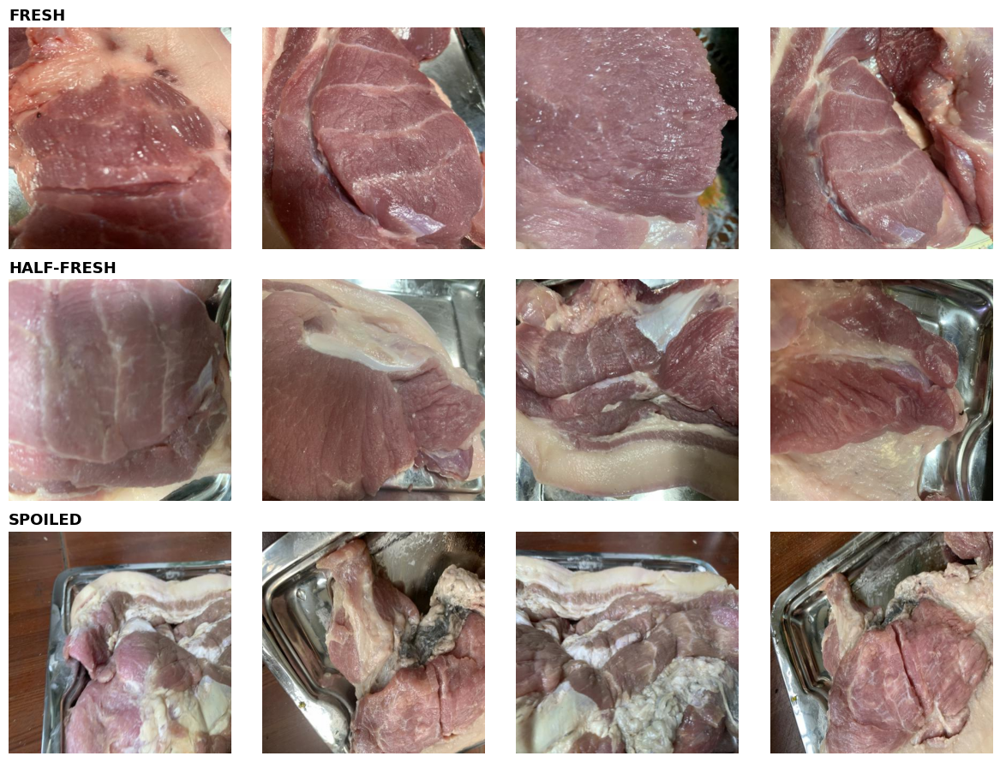

In [ ]:
def show_samples(df, n=4):
    fig, axes = plt.subplots(3, n, figsize=(3 * n, 9))
    for c in range(3):
        sub = df[df["label"] == c].sample(n, random_state=SEED)
        for j, p in enumerate(sub["path"]):
            axes[c, j].imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
            axes[c, j].axis("off")
            if j == 0:
                axes[c, j].set_title(CLASS_NAMES[c], loc="left", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()

show_samples(train_df)

## 5. Preprocessing: resize 224×224 dan normalisasi 0–1

Setiap gambar diproses dua tahap:
1. **Resize** menjadi 224×224 piksel (OpenCV membaca gambar dengan urutan warna **BGR**, nilai 0–255). Ukuran ini cukup besar untuk mempertahankan detail tekstur permukaan daging.
2. **Normalisasi**: nilai piksel dibagi 255 sehingga berada pada rentang 0–1.

Sel ini mencetak ukuran, tipe data, dan rentang nilai di tiap tahap supaya perubahannya terlihat jelas.

Ukuran asli          : (416, 416, 3)
Setelah resize       : (224, 224, 3) | tipe uint8 | nilai 0 - 255
Setelah normalisasi  : (224, 224, 3) | tipe float32 | nilai 0.0 - 1.0


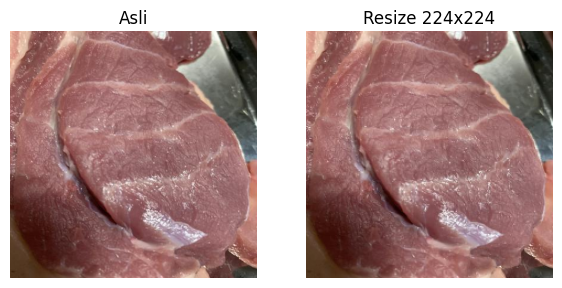

In [ ]:
def load_and_resize(path):
    img = cv2.imread(path)                 # uint8, urutan warna BGR, nilai 0-255
    if img is None:
        return None
    return cv2.resize(img, IMG_SIZE)       # 224 x 224

def normalize01(img_u8):
    return img_u8.astype(np.float32) / 255.0     # rescale 0-255 -> 0-1

p = train_df.iloc[0]["path"]
asli  = cv2.imread(p)
kecil = load_and_resize(p)
norm  = normalize01(kecil)
print("Ukuran asli          :", asli.shape)
print("Setelah resize       :", kecil.shape, "| tipe", kecil.dtype, "| nilai", kecil.min(), "-", kecil.max())
print("Setelah normalisasi  :", norm.shape,  "| tipe", norm.dtype,  "| nilai", round(float(norm.min()), 3), "-", round(float(norm.max()), 3))

fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
ax[0].imshow(cv2.cvtColor(asli, cv2.COLOR_BGR2RGB));  ax[0].set_title("Asli");          ax[0].axis("off")
ax[1].imshow(cv2.cvtColor(kecil, cv2.COLOR_BGR2RGB)); ax[1].set_title("Resize 224x224"); ax[1].axis("off")
plt.show()

## 6. Augmentasi (hanya data train) dan variasi cahaya untuk uji

Foto lapangan sering berbeda cahaya dan warna dari foto dataset. Karena itu augmentasi tidak hanya geometri, tetapi juga cahaya dan warna. Setiap salinan diberi kombinasi acak dari:
- **geometri**: rotasi ±20°, geser 10%, zoom 0.8×–1.2×, flip horizontal
- **cahaya & warna**: brightness 0.6–1.4, suhu warna (gain tiap channel ±15%), dan gamma 0.8–1.25

Fungsi `lighting_variant` membuat empat perubahan cahaya tetap (terang, gelap, hangat, dingin). Itu **hanya dipakai untuk mengevaluasi** ketahanan model, bukan untuk training. Sel ini menampilkan contoh keduanya.

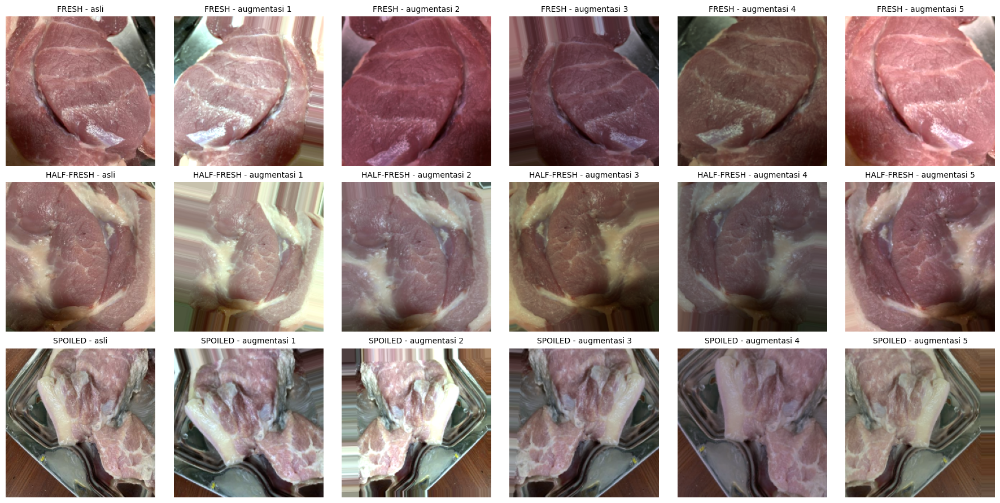

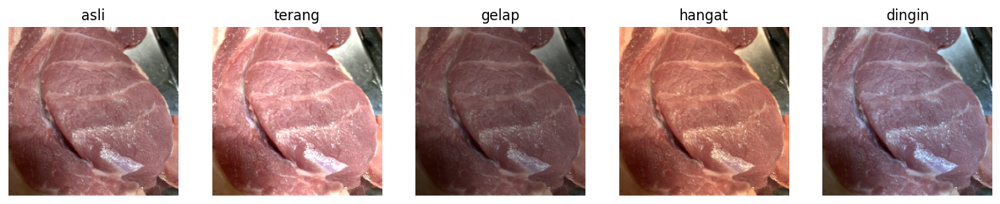

In [ ]:
def augment(img_u8, rng):
    """Augmentasi acak: geometri (rotasi, geser, zoom, flip) + cahaya & warna (brightness, gain per channel, gamma)."""
    h, w = img_u8.shape[:2]
    angle = rng.uniform(-AUG["rotation"], AUG["rotation"])
    zoom  = rng.uniform(1 - AUG["zoom"], 1 + AUG["zoom"])
    tx    = rng.uniform(-AUG["shift"], AUG["shift"]) * w
    ty    = rng.uniform(-AUG["shift"], AUG["shift"]) * h
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, zoom)
    M[0, 2] += tx; M[1, 2] += ty
    out = cv2.warpAffine(img_u8, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    if AUG["flip"] and rng.random() < 0.5:
        out = cv2.flip(out, 1)

    b     = rng.uniform(*AUG["brightness"])                                   # kecerahan keseluruhan
    gains = rng.uniform(1 - AUG["color_shift"], 1 + AUG["color_shift"], 3)    # suhu warna (gain tiap channel BGR)
    gamma = rng.uniform(*AUG["gamma"])                                        # kontras tengah
    f = np.clip(out.astype(np.float32) / 255.0 * gains * b, 0, 1) ** gamma
    return (f * 255).astype(np.uint8)

def lighting_variant(img_u8, name):
    """Perubahan cahaya tetap (deterministik) untuk uji ketahanan."""
    f = img_u8.astype(np.float32)
    if   name == "terang": f = f * 1.35
    elif name == "gelap":  f = f * 0.65
    elif name == "hangat": f = f * np.array([0.85, 1.0, 1.15])     # lebih merah/kuning (urutan BGR)
    elif name == "dingin": f = f * np.array([1.15, 1.0, 0.85])     # lebih biru
    return np.clip(f, 0, 255).astype(np.uint8)

# (a) Gambar asli + 5 hasil augmentasi tiap kelas
rng_demo = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 6, figsize=(18, 9))
for c in range(3):
    base = load_and_resize(train_df[train_df["label"] == c].iloc[0]["path"])
    for j, v in enumerate([base] + [augment(base, rng_demo) for _ in range(5)]):
        axes[c, j].imshow(cv2.cvtColor(v, cv2.COLOR_BGR2RGB)); axes[c, j].axis("off")
        axes[c, j].set_title(f"{CLASS_NAMES[c]} - " + ("asli" if j == 0 else f"augmentasi {j}"), fontsize=10)
plt.tight_layout(); plt.show()

# (b) Variasi cahaya untuk uji ketahanan
base = load_and_resize(train_df[train_df["label"] == 0].iloc[0]["path"])
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
for ax, name in zip(axes, ["asli"] + SHIFT_NAMES):
    v = base if name == "asli" else lighting_variant(base, name)
    ax.imshow(cv2.cvtColor(v, cv2.COLOR_BGR2RGB)); ax.set_title(name); ax.axis("off")
plt.show()

## 7. Segmentasi: fungsi pemisah daging dari latar

Tujuannya agar fitur hanya dihitung dari area daging, bukan dari nampan, plastik, atau meja. Tahapannya:

0. **Koreksi warna cahaya (white-patch)**: tiap channel disesuaikan dengan area paling terang, supaya warna lampu (kuning/biru) tidak mengacaukan ambang warna. Koreksi ini **hanya dipakai untuk menentukan mask**, bukan untuk fitur warna.
1. **Ambang warna HSV**: piksel dianggap daging jika coraknya merah/pink/coklat (H ≤ 55° atau H ≥ 290°), cukup pekat (S ≥ 0.12), dan tidak terlalu gelap (V ≥ 0.10).
2. **Buang meja/nampan**: meja kayu dan nampan memiliki corak yang mirip daging, sehingga lolos tahap 1. Cirinya: kekuningan-coklat (sudut warna Lab ≥ 40°), gelap (V < 0.65), cukup pekat (S ≥ 0.25), dan **menyentuh tepi gambar**. Area seperti ini dibuang. Bercak gelap di tengah daging (misalnya jamur) tidak ikut dibuang karena tidak menyentuh tepi.
3. **Closing** menutup celah kecil, **Opening** membuang bintik kecil.
4. **Komponen terbesar** dipertahankan sebagai objek utama.
5. **Isi lubang** supaya bercak putih/jamur di dalam daging tetap ikut terhitung.

Jika area hasil segmentasi kurang dari 10% gambar, segmentasi dianggap gagal dan seluruh gambar dipakai (*fallback*).

**Cara menyetel:** kalau meja/nampan masih terlihat, turunkan `WOOD_HAB` (misalnya 35) atau naikkan `WOOD_V` (misalnya 0.70). Kalau daging yang kecokelatan ikut terbuang, lakukan sebaliknya. Jangan menaikkan atau menurunkan `S_MIN` untuk mengatasi meja, karena meja kayu justru lebih pekat daripada daging yang pucat.

In [ ]:
# Parameter segmentasi (bisa disesuaikan setelah melihat hasil visualisasi)
S_MIN, V_MIN                = 0.12, 0.10      # saturasi & kecerahan minimum (skala 0-1)
HUE_MAX_LOW, HUE_MIN_HIGH   = 55, 290         # merah/pink/coklat: H <= 55 derajat atau H >= 290 derajat
K_BLUR, K_CLOSE, K_OPEN     = 7, 13, 9        # ukuran kernel (untuk citra 224x224)
MIN_COVER                   = 0.10            # jika area segmentasi < 10% gambar -> dianggap gagal

# Pembuang meja kayu / nampan: area kekuningan-coklat, cukup gelap, cukup pekat, DAN menyentuh tepi gambar
WOOD_HAB, WOOD_V, WOOD_S    = 40, 0.65, 0.25  # sudut warna Lab >= 40 derajat, V < 0.65, S >= 0.25
WOOD_MIN_FRAC               = 0.01            # area minimal (1% gambar) agar dibuang

def white_patch(img01, pct=98, limit=(0.7, 1.4)):
    """Koreksi warna cahaya sederhana (white-patch): tiap channel disesuaikan dengan area paling terang.
    Hanya dipakai untuk menentukan mask segmentasi, TIDAK untuk fitur warna."""
    p = np.percentile(img01.reshape(-1, 3), pct, axis=0) + 1e-6
    gain = np.clip(p.mean() / p, *limit)
    return np.clip(img01 * gain, 0, 1).astype(np.float32)

def segment_steps(img01):
    blur = cv2.GaussianBlur(white_patch(img01), (K_BLUR, K_BLUR), 0)
    hsv  = cv2.cvtColor(blur, cv2.COLOR_BGR2HSV)            # H: 0-360, S & V: 0-1
    lab  = cv2.cvtColor(blur, cv2.COLOR_BGR2Lab)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    a, b = lab[..., 1], lab[..., 2]
    hab = np.degrees(np.arctan2(b, np.maximum(a, 1e-3)))    # sudut warna Lab: pink/merah kecil, kuning/coklat besar

    # 1) ambang warna daging (merah/pink/coklat)
    raw = (((h <= HUE_MAX_LOW) | (h >= HUE_MIN_HIGH)) & (s >= S_MIN) & (v >= V_MIN)).astype(np.uint8)

    # 2) buang meja kayu / nampan: area kekuningan-gelap-pekat yang MENYENTUH TEPI gambar
    kayu = ((hab >= WOOD_HAB) & (v < WOOD_V) & (s >= WOOD_S)).astype(np.uint8)
    kayu = cv2.morphologyEx(kayu, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7)))
    n, lab_k, stats, _ = cv2.connectedComponentsWithStats(kayu, connectivity=8)
    H, W = kayu.shape; buang = np.zeros_like(kayu)
    for k in range(1, n):
        x0, y0, w0, h0, area = stats[k]
        menyentuh_tepi = x0 <= 2 or y0 <= 2 or x0 + w0 >= W - 2 or y0 + h0 >= H - 2
        if menyentuh_tepi and area >= WOOD_MIN_FRAC * H * W:
            buang[lab_k == k] = 1
    nokayu = (raw & (buang == 0)).astype(np.uint8)

    # 3) rapikan: closing, opening, komponen terbesar, isi lubang
    closed = cv2.morphologyEx(nokayu, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (K_CLOSE, K_CLOSE)))
    opened = cv2.morphologyEx(closed,  cv2.MORPH_OPEN,  cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (K_OPEN, K_OPEN)))

    n, lab2, stats2, _ = cv2.connectedComponentsWithStats(opened, connectivity=8)
    if n > 1:
        k = 1 + np.argmax(stats2[1:, cv2.CC_STAT_AREA])
        largest = (lab2 == k).astype(np.uint8)
    else:
        largest = opened
    filled = ndi.binary_fill_holes(largest > 0).astype(np.uint8)
    return {"raw": raw, "nokayu": nokayu, "closed": closed, "opened": opened, "largest": largest, "final": filled}

def segment_meat(img01):
    """Return (mask 0/1, fallback?). Jika segmentasi gagal, seluruh gambar dipakai."""
    final = segment_steps(img01)["final"]
    if final.mean() < MIN_COVER:
        return np.ones(final.shape, np.uint8), True
    return final, False

def apply_mask(img_u8, mask):
    out = img_u8.copy(); out[mask == 0] = (0, 0, 0)
    return out

print("Fungsi segmentasi siap")

Fungsi segmentasi siap


## 8. Visualisasi tahapan segmentasi

Menampilkan satu gambar (kelas SPOILED) melewati setiap tahap segmentasi, dari gambar asli sampai mask akhir. Area putih = daging, hitam = latar. Dari sini terlihat peran tiap tahap, misalnya *isi lubang* yang menutup bercak di dalam daging.

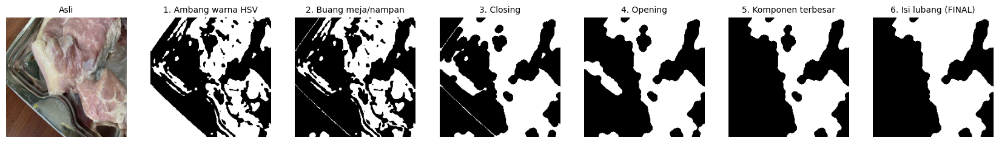

In [ ]:
img = load_and_resize(train_df[train_df["label"] == 2].iloc[0]["path"])   # contoh dari kelas SPOILED
steps = segment_steps(normalize01(img))

panels = [("Asli", None), ("1. Ambang warna HSV", "raw"), ("2. Buang meja/nampan", "nokayu"), ("3. Closing", "closed"),
          ("4. Opening", "opened"), ("5. Komponen terbesar", "largest"), ("6. Isi lubang (FINAL)", "final")]
fig, axes = plt.subplots(1, 7, figsize=(21, 3.6))
for ax, (title, key) in zip(axes, panels):
    if key is None: ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:           ax.imshow(steps[key], cmap="gray")
    ax.set_title(title, fontsize=10); ax.axis("off")
plt.show()

## 9. Hasil segmentasi pada banyak gambar

Tiap kelas ditampilkan 4 gambar: baris atas gambar asli, baris bawah hasil segmentasi (latar dihitamkan) beserta persentase area yang terdeteksi sebagai daging.

**Periksa dengan teliti.** Kalau banyak gambar yang dagingnya terpotong, atau latar masih ikut terbawa, ubah parameter di Sel 8 (misalnya turunkan `S_MIN` agar daging yang pucat ikut terbawa), lalu jalankan ulang dari Sel 8. Segmentasi berbasis warna punya keterbatasan: urat/lemak putih di tepi daging dan daging yang sangat pucat atau keabu-abuan bisa ikut terpotong.

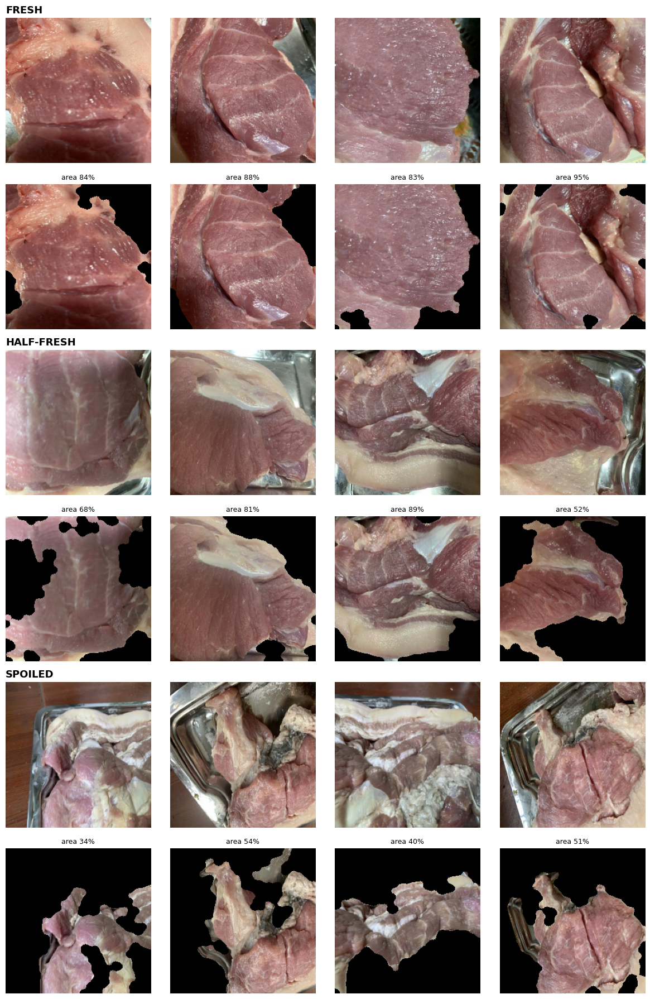

In [ ]:
def show_segmentation(df, n=4):
    fig, axes = plt.subplots(6, n, figsize=(3 * n, 18))
    for c in range(3):
        sub = df[df["label"] == c].sample(n, random_state=SEED)
        for j, p in enumerate(sub["path"]):
            img = load_and_resize(p)
            mask, fb = segment_meat(normalize01(img))
            axes[2 * c, j].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[2 * c, j].axis("off")
            axes[2 * c + 1, j].imshow(cv2.cvtColor(apply_mask(img, mask), cv2.COLOR_BGR2RGB)); axes[2 * c + 1, j].axis("off")
            axes[2 * c + 1, j].set_title(f"area {mask.mean()*100:.0f}%" + (" (gagal)" if fb else ""), fontsize=9)
            if j == 0:
                axes[2 * c, j].set_title(CLASS_NAMES[c], loc="left", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()

show_segmentation(train_df)

## 10. Histogram warna per kelas (sebelum vs sesudah segmentasi)

**Histogram** menghitung berapa banyak piksel pada tiap rentang nilai. Di sini dipakai ruang warna yang memisahkan warna dari kecerahan:
- **a\*** (hijau ↔ merah) dan **b\*** (biru ↔ kuning) dari ruang warna Lab
- **Hue** (corak) dan **Saturasi** (kepekatan) dari HSV. Hue digeser 40° agar warna merah, yang di ujung skala hue (0° dan 360°), menjadi satu rentang menyambung.

Garis **putus-putus** = seluruh gambar, garis **tegas** = hanya area daging. Selisih keduanya menunjukkan seberapa besar latar belakang mengganggu fitur warna jika tidak disegmentasi.

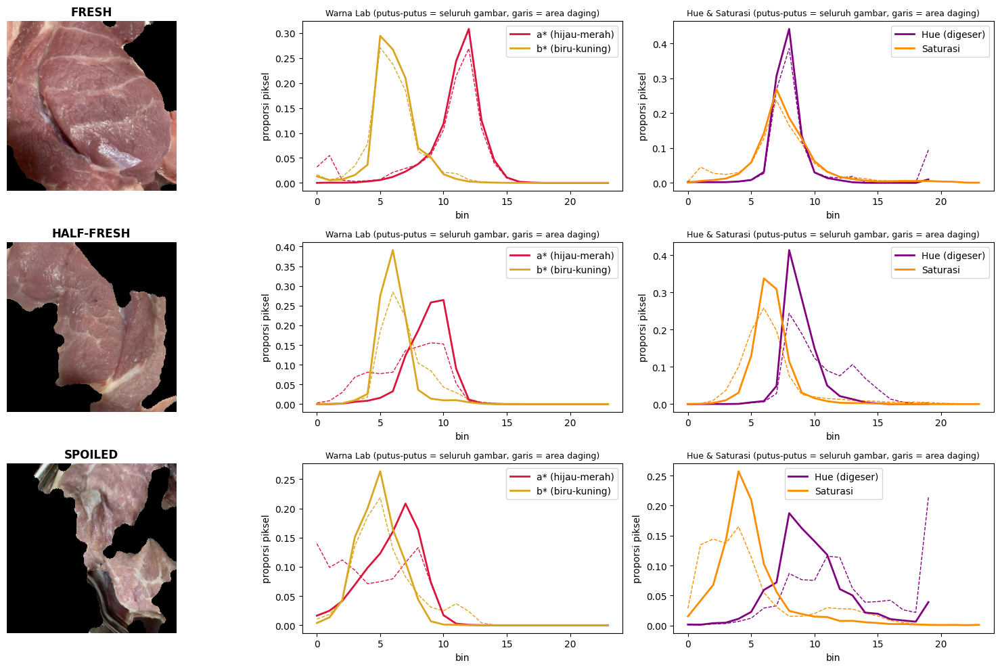

In [ ]:
def prop_hist(vals, bins, rng):
    """Histogram sebagai proporsi (jumlah semua bin = 1)."""
    h, _ = np.histogram(np.clip(vals, rng[0], rng[1]), bins=bins, range=rng)
    return h / max(h.sum(), 1)

def l2_hist(vals, bins, rng):
    """Histogram dinormalisasi L2 (tidak bergantung pada jumlah piksel)."""
    h, _ = np.histogram(np.clip(vals, rng[0], rng[1]), bins=bins, range=rng)
    h = h.astype(np.float64); n = np.linalg.norm(h)
    return h / n if n > 0 else h

def shift_hue(h_deg):
    """Geser hue 40 derajat agar warna merah (320-360 dan 0-50) menjadi satu rentang menyambung (0-90)."""
    return (h_deg + 40) % 360

def show_hist_per_class(df):
    fig, axes = plt.subplots(3, 3, figsize=(16, 10))
    for c in range(3):
        img = load_and_resize(df[df["label"] == c].iloc[0]["path"])
        img01 = normalize01(img); mask, _ = segment_meat(img01); m = mask > 0
        lab = cv2.cvtColor(img01, cv2.COLOR_BGR2Lab); hsv = cv2.cvtColor(img01, cv2.COLOR_BGR2HSV)
        axes[c, 0].imshow(cv2.cvtColor(apply_mask(img, mask), cv2.COLOR_BGR2RGB)); axes[c, 0].axis("off")
        axes[c, 0].set_title(CLASS_NAMES[c], fontweight="bold")
        full = np.ones_like(m)
        for sel, ls, lw in ((full, "--", 1), (m, "-", 2)):
            axes[c, 1].plot(prop_hist(lab[..., 1][sel], 24, (-5, 45)), ls, color="crimson", lw=lw, label="a* (hijau-merah)" if ls == "-" else None)
            axes[c, 1].plot(prop_hist(lab[..., 2][sel], 24, (-5, 45)), ls, color="goldenrod", lw=lw, label="b* (biru-kuning)" if ls == "-" else None)
            axes[c, 2].plot(prop_hist(shift_hue(hsv[..., 0][sel]), 20, (0, 100)), ls, color="purple", lw=lw, label="Hue (digeser)" if ls == "-" else None)
            axes[c, 2].plot(prop_hist(hsv[..., 1][sel], 24, (0, 1)), ls, color="darkorange", lw=lw, label="Saturasi" if ls == "-" else None)
        axes[c, 1].set_title("Warna Lab (putus-putus = seluruh gambar, garis = area daging)", fontsize=9)
        axes[c, 2].set_title("Hue & Saturasi (putus-putus = seluruh gambar, garis = area daging)", fontsize=9)
        for a in axes[c, 1:]:
            a.set_xlabel("bin"); a.set_ylabel("proporsi piksel"); a.legend()
    plt.tight_layout(); plt.show()

show_hist_per_class(train_df)

## 11. Visualisasi tekstur dengan LBP (dua skala)

**Local Binary Pattern (LBP)** membandingkan tiap piksel dengan piksel di sekelilingnya pada gambar grayscale, lalu mengubah pola naik-turunnya menjadi kode. Hasilnya ringkasan tekstur permukaan, dan nilainya **tidak berubah oleh perubahan kecerahan** yang merata, sehingga cocok untuk foto dengan cahaya berbeda.

Dua skala ditampilkan: radius 1 dengan 8 titik (tekstur halus) dan radius 3 dengan 24 titik (tekstur lebih kasar, misalnya bercak atau lendir). Hanya area daging yang ditampilkan.

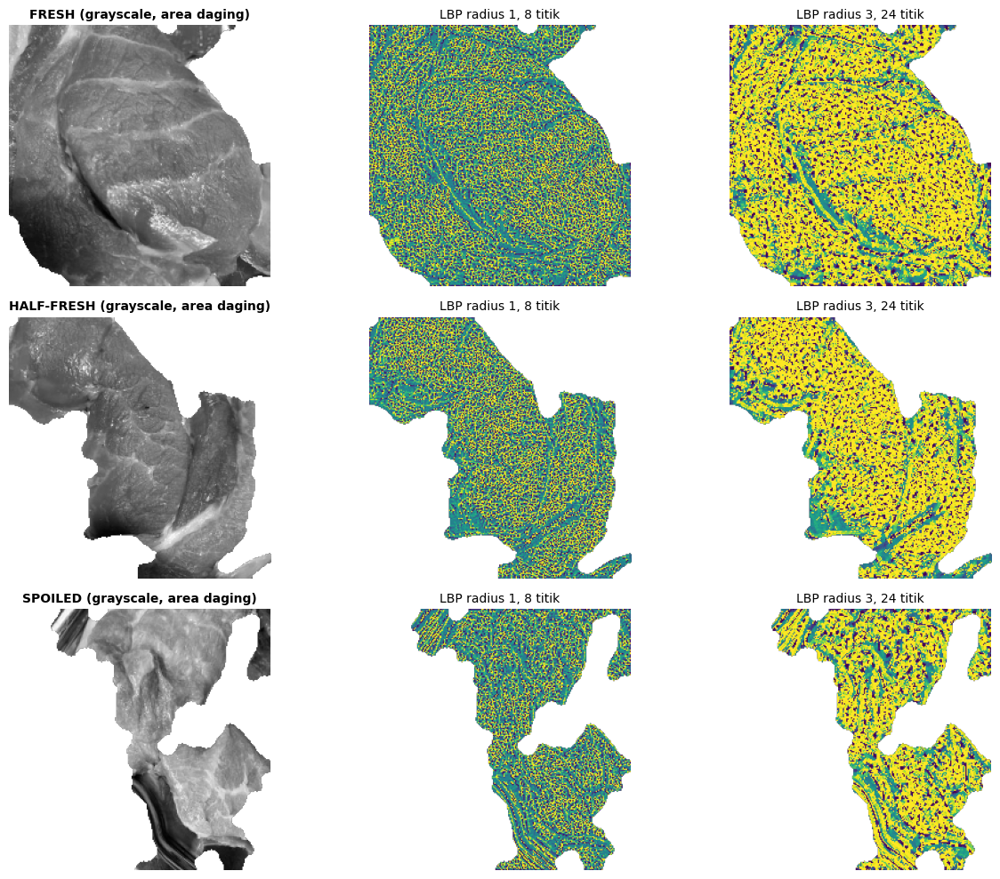

In [ ]:
def show_lbp(df):
    fig, axes = plt.subplots(3, 3, figsize=(13, 10))
    for c in range(3):
        img = load_and_resize(df[df["label"] == c].iloc[0]["path"])
        img01 = normalize01(img); mask, _ = segment_meat(img01)
        gray = cv2.cvtColor(img01, cv2.COLOR_BGR2GRAY)
        axes[c, 0].imshow(np.ma.masked_where(mask == 0, gray), cmap="gray"); axes[c, 0].axis("off")
        axes[c, 0].set_title(f"{CLASS_NAMES[c]} (grayscale, area daging)", fontweight="bold", fontsize=10)
        for j, (r, p) in enumerate([(1, 8), (3, 24)], start=1):
            lbp = local_binary_pattern(gray, p, r, method="uniform")
            axes[c, j].imshow(np.ma.masked_where(mask == 0, lbp), cmap="viridis"); axes[c, j].axis("off")
            axes[c, j].set_title(f"LBP radius {r}, {p} titik", fontsize=10)
    plt.tight_layout(); plt.show()

show_lbp(train_df)

## 12. Fungsi ekstraksi fitur (dua set)

Setiap gambar diubah menjadi vektor fitur, hanya dari **area daging** (hasil segmentasi). Dua set fitur dibuat supaya bisa dibandingkan:

**Set A: Dasar (202 fitur)**: histogram 32 bin untuk R, G, B, H, S, V, ditambah histogram LBP (radius 1, 8 titik).

**Set B: Lanjutan (183 fitur)**, dirancang agar tidak mudah terkecoh perubahan cahaya:
1. Histogram warna **a\*, b\*** (Lab), **hue**, dan **saturasi**, yang memisahkan warna dari kecerahan
2. **Momen warna** (rata-rata, simpangan baku, kemiringan) dan ukuran kontras relatif luminans
3. **Luminans relatif**: kecerahan dibagi rata-rata area daging, sehingga foto terang dan gelap menjadi sebanding
4. **LBP tiga skala** (radius 1, 2, 3)
5. **Kekuatan tepi** (gradien Sobel) pada gambar yang dinormalisasi
6. **Rasio piksel mengkilap** (indikasi lendir/pantulan) dan **piksel pucat** (indikasi lemak/jamur)

Semua histogram warna dinormalisasi L2 agar tidak bergantung pada jumlah piksel (luas daging berbeda-beda setelah segmentasi).

In [ ]:
# ---------- Fitur Set A: "Dasar" (RGB + HSV + LBP), hanya dari area daging ----------
def feat_dasar(img01, mask):
    m = mask > 0
    rgb = img01[..., ::-1]
    hsv = cv2.cvtColor(img01, cv2.COLOR_BGR2HSV).copy(); hsv[..., 0] /= 360.0
    chans = [rgb[..., 0], rgb[..., 1], rgb[..., 2], hsv[..., 0], hsv[..., 1], hsv[..., 2]]
    parts = [l2_hist(c[m], 32, (0, 1)) for c in chans]                    # 6 x 32 = 192
    gray = cv2.cvtColor(img01, cv2.COLOR_BGR2GRAY)
    lbp = local_binary_pattern(gray, 8, 1, method="uniform")
    parts.append(prop_hist(lbp[m], 10, (0, 10)))                          # 10
    return np.concatenate(parts)                                          # 202

# ---------- Fitur Set B: "Lanjutan" (tahan perubahan cahaya + tekstur multi-skala) ----------
B_LAYOUT = [("a*", 24), ("b*", 24), ("Hue", 20), ("Saturasi", 24), ("Momen warna", 11),
            ("Luminans relatif", 16), ("LBP R1-P8", 10), ("LBP R2-P16", 18), ("LBP R3-P24", 26),
            ("Gradien", 8), ("Rasio kilap/pucat", 2)]

def feat_lanjutan(img01, mask):
    m = mask > 0
    lab = cv2.cvtColor(img01, cv2.COLOR_BGR2Lab); hsv = cv2.cvtColor(img01, cv2.COLOR_BGR2HSV)
    L, a, b = lab[..., 0][m], lab[..., 1][m], lab[..., 2][m]
    h, s, v = hsv[..., 0][m], hsv[..., 1][m], hsv[..., 2][m]

    # 1) Warna tanpa kecerahan: kromatisitas a*, b* + hue & saturasi
    parts = [l2_hist(a, 24, (-5, 45)), l2_hist(b, 24, (-5, 45)),
             l2_hist(shift_hue(h), 20, (0, 100)), l2_hist(s, 24, (0, 1))]

    # 2) Momen warna (rata-rata, simpangan baku, kemiringan); untuk L hanya ukuran kontras relatif
    def mom(x): return [x.mean(), x.std(), float(np.nan_to_num(skew(x)))]
    parts.append(np.array(mom(a) + mom(b) + mom(s) + [L.std() / (L.mean() + 1e-6), float(np.nan_to_num(skew(L)))]))

    # 3) Distribusi luminans relatif (dibagi rata-rata area daging -> tidak bergantung terang/gelap foto)
    parts.append(l2_hist(L / (L.mean() + 1e-6), 16, (0, 2)))

    # 4) Tekstur LBP multi-skala (LBP tidak berubah oleh perubahan kecerahan/kontras monoton)
    gray = cv2.cvtColor(img01, cv2.COLOR_BGR2GRAY)
    for r, p in [(1, 8), (2, 16), (3, 24)]:
        lbp = local_binary_pattern(gray, p, r, method="uniform")
        parts.append(prop_hist(lbp[m], p + 2, (0, p + 2)))

    # 5) Kekuatan tepi/tekstur (gradien Sobel pada gray yang dinormalisasi)
    gn = gray / (gray[m].mean() + 1e-6)
    gx = cv2.Sobel(gn, cv2.CV_32F, 1, 0, ksize=3); gy = cv2.Sobel(gn, cv2.CV_32F, 0, 1, ksize=3)
    parts.append(prop_hist(np.sqrt(gx ** 2 + gy ** 2)[m], 8, (0, 1.0)))

    # 6) Rasio piksel mengkilap (kilap/lendir) dan piksel pucat (lemak/jamur)
    parts.append(np.array([np.mean((v > 0.92) & (s < 0.25)), np.mean((s < 0.18) & (v > 0.45) & (v <= 0.92))]))
    return np.concatenate(parts)

SETS = {"Dasar": feat_dasar, "Lanjutan": feat_lanjutan}

_img = normalize01(load_and_resize(train_df.iloc[0]["path"])); _mask, _ = segment_meat(_img)
dims = {name: f(_img, _mask).shape[0] for name, f in SETS.items()}
assert dims["Lanjutan"] == sum(n for _, n in B_LAYOUT)
print("Jumlah fitur per gambar:", dims)

Jumlah fitur per gambar: {'Dasar': 202, 'Lanjutan': 183}


## 13. Ekstraksi fitur seluruh dataset

Urutan untuk setiap gambar: baca → resize → (augmentasi untuk salinan) → normalisasi 0–1 → **segmentasi** → ekstraksi fitur kedua set.

- **Data train**: gambar asli + `N_AUG` salinan augmentasi.
- **Data test**: gambar asli + 4 variasi cahaya (terang, gelap, hangat, dingin) untuk uji ketahanan. Variasi ini hanya dievaluasi, tidak dipakai untuk training.

Proses berjalan paralel di semua core CPU dan butuh beberapa menit. Hasil disimpan ke `fitur_svm_v3.npz`. Tiap sampel membawa nomor gambar asalnya (`gtr`) yang dipakai agar cross-validation tidak membocorkan salinan augmentasi.

In [ ]:
def process_image(path, seed, n_aug, with_shifts):
    """Satu gambar -> fitur untuk gambar asli, salinan augmentasi, dan (opsional) variasi cahaya."""
    base = load_and_resize(path)
    if base is None:
        return None
    rng = np.random.default_rng(seed)
    versions = [("asli", base)] + [(f"aug{i}", augment(base, rng)) for i in range(n_aug)]
    if with_shifts:
        versions += [(nm, lighting_variant(base, nm)) for nm in SHIFT_NAMES]
    out = []
    for tag, im in versions:
        img01 = normalize01(im)
        mask, fb = segment_meat(img01)                                   # segmentasi dulu, lalu ekstraksi fitur
        out.append((tag, {n: f(img01, mask) for n, f in SETS.items()}, fb))
    return out

def extract_dataset(df, n_aug, with_shifts, seed=SEED):
    jobs = (delayed(process_image)(p, seed + i, n_aug, with_shifts) for i, p in enumerate(tqdm(df["path"])))
    results = Parallel(n_jobs=-1)(jobs)
    X = {n: [] for n in SETS}; y, grp, tag, fails = [], [], [], 0
    for gi, (res, lab) in enumerate(zip(results, df["label"])):
        if res is None:
            continue
        for t, feats, fb in res:
            for n in SETS: X[n].append(feats[n])
            y.append(lab); grp.append(gi); tag.append(t); fails += int(fb)
    print(f"Selesai: {len(y)} sampel | segmentasi gagal (fallback): {fails}")
    return {n: np.array(v) for n, v in X.items()}, np.array(y), np.array(grp), np.array(tag)

# Train: gambar asli + N_AUG salinan augmentasi | Test: gambar asli + 4 variasi cahaya (untuk uji ketahanan)
Xtr, ytr, gtr, ttr = extract_dataset(train_df, n_aug=N_AUG, with_shifts=False)
Xte, yte, gte, tte = extract_dataset(test_df,  n_aug=0,     with_shifts=True)
orig_tr = (ttr == "asli")
print("Train asli:", int(orig_tr.sum()), "| salinan augmentasi:", int((~orig_tr).sum()), "| test (asli + variasi cahaya):", len(yte))
np.savez("fitur_svm_v3.npz", ytr=ytr, gtr=gtr, ttr=ttr, yte=yte, tte=tte,
         **{f"Xtr_{n}": v for n, v in Xtr.items()}, **{f"Xte_{n}": v for n, v in Xte.items()})

  0%|          | 0/1815 [00:00<?, ?it/s]

Selesai: 5445 sampel | segmentasi gagal (fallback): 63


  0%|          | 0/451 [00:00<?, ?it/s]

Selesai: 2255 sampel | segmentasi gagal (fallback): 8
Train asli: 1815 | salinan augmentasi: 3630 | test (asli + variasi cahaya): 2255


## 14. Rata-rata fitur tiap kelas (set Lanjutan)

Garis tiap kelas adalah **rata-rata** fitur dari seluruh gambar train asli. Kalau garis tiga kelas saling berjauhan, kelompok fitur itu bagus untuk membedakan kelas. Kalau saling menumpuk, kelompok itu kurang berguna. Tabel di bawahnya merangkum fitur non-histogram (momen warna dan rasio kilap/pucat) per kelas.

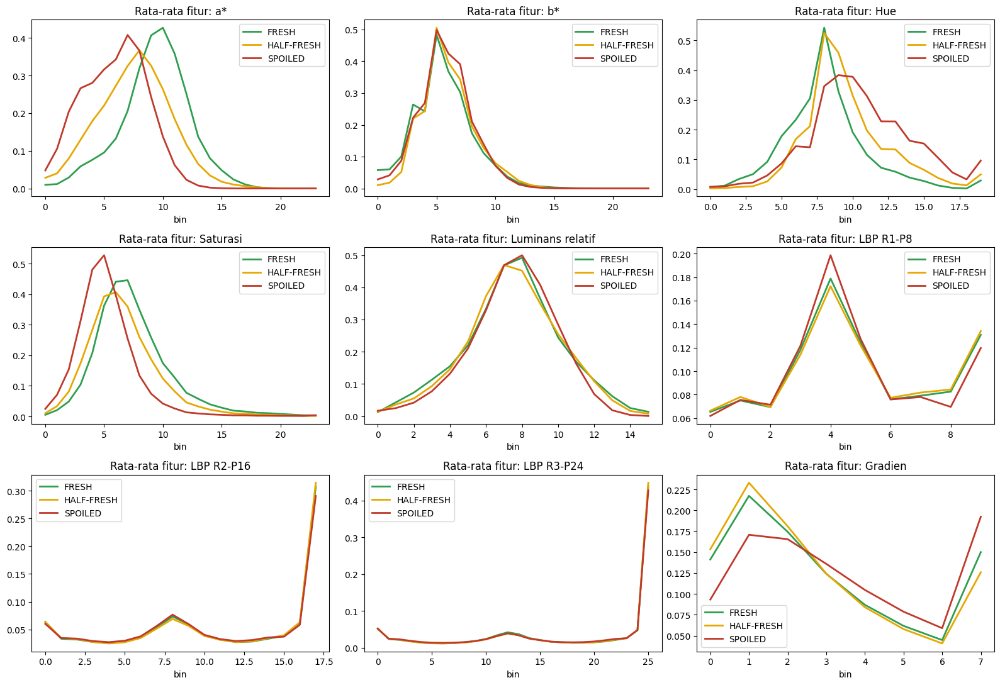

,a* rata2,a* std,a* skew,b* rata2,b* std,b* skew,S rata2,S std,S skew,L std/rata2,L skew,rasio kilap,rasio pucat
FRESH,15.378,4.937,-0.668,7.497,4.013,0.614,0.331,0.122,1.219,0.330,-0.096,0.002,0.076
HALF-FRESH,11.678,4.673,-0.459,8.323,3.691,0.527,0.292,0.098,1.113,0.311,-0.015,0.001,0.141
SPOILED,8.275,4.961,-0.142,7.937,3.779,0.160,0.238,0.098,1.583,0.284,-0.387,0.002,0.248


In [ ]:
edges = np.cumsum([0] + [n for _, n in B_LAYOUT])
hist_groups = [(name, edges[i], edges[i + 1]) for i, (name, _) in enumerate(B_LAYOUT) if name not in ("Momen warna", "Rasio kilap/pucat")]

fig, axes = plt.subplots(3, 3, figsize=(16, 11)); axes = axes.ravel()
for ax, (name, a, b) in zip(axes, hist_groups):
    for c in range(3):
        ax.plot(Xtr["Lanjutan"][(ytr == c) & orig_tr][:, a:b].mean(axis=0), color=CLASS_COLORS[c], label=CLASS_NAMES[c], lw=2)
    ax.set_title(f"Rata-rata fitur: {name}"); ax.set_xlabel("bin"); ax.legend()
plt.tight_layout(); plt.show()

# Fitur non-histogram: momen warna dan rasio kilap/pucat (rata-rata per kelas)
mom_names = ["a* rata2", "a* std", "a* skew", "b* rata2", "b* std", "b* skew", "S rata2", "S std", "S skew", "L std/rata2", "L skew"]
ia, ib = edges[4], edges[5]
ir, ie = edges[-2], edges[-1]
cols = mom_names + ["rasio kilap", "rasio pucat"]
tbl = pd.DataFrame([np.concatenate([Xtr["Lanjutan"][(ytr == c) & orig_tr][:, ia:ib].mean(axis=0),
                                    Xtr["Lanjutan"][(ytr == c) & orig_tr][:, ir:ie].mean(axis=0)]) for c in range(3)],
                   index=CLASS_NAMES, columns=cols)
display(tbl.round(3))

## 15. Tuning parameter SVM dengan cross-validation

Model: `StandardScaler` + SVM kernel RBF dengan `class_weight="balanced"` (jumlah gambar tiap kelas tidak persis sama). Parameter dicari dengan mencoba kombinasi:
- **C** ∈ {1, 10, 100}
- **gamma** = pengali (0.3, 1, 3) ÷ jumlah fitur

Pembagian cross-validation (3 lipatan) **dikelompokkan per gambar asal**: gambar asli dan seluruh salinan augmentasinya selalu berada di lipatan yang sama, sehingga tidak ada kebocoran data. Setiap lipatan dinilai pada dua kelompok:
- **gambar asli** (kondisi bersih)
- **salinan augmentasi** (posisi dan cahaya berubah, bukan bagian dari training di lipatan itu)

Skor akhir = rata-rata keduanya, supaya model yang bagus di data bersih tapi rapuh terhadap cahaya tidak terpilih. Hasil ditampilkan untuk kedua set fitur.

In [ ]:
def make_pipeline(C=10, gamma="scale", probability=False):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=C, gamma=gamma, class_weight="balanced",
                    probability=probability, decision_function_shape="ovr", random_state=SEED)),
    ])

# Lipatan dikelompokkan per gambar asal: gambar asli dan salinan augmentasinya tidak pernah terpisah antar lipatan
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
folds = list(sgkf.split(np.zeros(len(ytr)), ytr, gtr))

def run_fold(set_name, C, mult, fi):
    tr_idx, va_idx = folds[fi]
    X = Xtr[set_name]; gamma = mult / X.shape[1]            # 'scale' pada fitur terstandarisasi = 1 / jumlah_fitur
    pipe = make_pipeline(C, gamma).fit(X[tr_idx], ytr[tr_idx])
    o = va_idx[orig_tr[va_idx]]; a = va_idx[~orig_tr[va_idx]]
    acc_o = accuracy_score(ytr[o], pipe.predict(X[o]))
    acc_a = accuracy_score(ytr[a], pipe.predict(X[a])) if len(a) else np.nan
    return set_name, C, mult, acc_o, acc_a

tasks = [(s, C, m, fi) for s in SETS for C in C_GRID for m in GAMMA_MULT for fi in range(N_SPLITS)]
res = Parallel(n_jobs=-1)(delayed(run_fold)(*t) for t in tqdm(tasks))
cv_df = pd.DataFrame(res, columns=["fitur", "C", "gamma_x", "acc_asli", "acc_aug"])
cv_df = cv_df.groupby(["fitur", "C", "gamma_x"], as_index=False).mean()
cv_df["skor"] = cv_df[["acc_asli", "acc_aug"]].mean(axis=1)       # rata-rata gambar asli & gambar berubah cahaya/posisi

best = {}
for s in SETS:
    sub = cv_df[cv_df["fitur"] == s].sort_values("skor", ascending=False)
    best[s] = sub.iloc[0]
    print(f"\n=== Fitur {s}: 5 kombinasi terbaik ===")
    display(sub.head(5).assign(**{c: sub.head(5)[c].map(lambda x: f"{x*100:.2f}%") for c in ["acc_asli", "acc_aug", "skor"]}))

summary_cv = pd.DataFrame([{"fitur": s, "C terbaik": b["C"], "gamma_x terbaik": b["gamma_x"],
                            "CV gambar asli": f"{b['acc_asli']*100:.2f}%", "CV gambar augmentasi": f"{b['acc_aug']*100:.2f}%",
                            "skor": b["skor"]} for s, b in best.items()])
print("\nRingkasan hasil tuning:"); display(summary_cv)

  0%|          | 0/54 [00:00<?, ?it/s]


=== Fitur Dasar: 5 kombinasi terbaik ===


,fitur,C,gamma_x,acc_asli,acc_aug,skor
6,Dasar,100,0.3,94.33%,76.14%,85.23%
4,Dasar,10,1.0,94.88%,73.61%,84.24%
7,Dasar,100,1.0,95.76%,71.90%,83.83%
3,Dasar,10,0.3,90.74%,76.64%,83.69%
8,Dasar,100,3.0,95.87%,68.18%,82.02%



=== Fitur Lanjutan: 5 kombinasi terbaik ===


,fitur,C,gamma_x,acc_asli,acc_aug,skor
16,Lanjutan,100,1.0,97.41%,83.28%,90.34%
13,Lanjutan,10,1.0,96.97%,83.20%,90.08%
15,Lanjutan,100,0.3,96.42%,83.50%,89.96%
12,Lanjutan,10,0.3,94.77%,84.77%,89.77%
14,Lanjutan,10,3.0,97.96%,78.95%,88.46%



Ringkasan hasil tuning:


,fitur,C terbaik,gamma_x terbaik,CV gambar asli,CV gambar augmentasi,skor
0,Dasar,100,0.3,94.33%,76.14%,0.852342
1,Lanjutan,100,1.0,97.41%,83.28%,0.903444


## 16. Model akhir dan evaluasi pada data test

Model akhir dilatih (dengan estimasi probabilitas) memakai parameter terbaik tiap set fitur pada seluruh data train. **Set fitur terpilih ditentukan dari skor cross-validation**, bukan dari data test, supaya data test tetap murni untuk evaluasi akhir.

Sel ini menampilkan classification report (precision, recall, F1 per kelas) dan **confusion matrix** untuk kedua model pada gambar test asli. Baris = kelas sebenarnya, kolom = prediksi. Angka di luar diagonal adalah kesalahan. Gambar hanya ditampilkan, tidak diunduh.

Fitur terpilih berdasarkan cross-validation: Lanjutan
SVM fitur Dasar | akurasi test: 94.90%
              precision    recall  f1-score   support

       FRESH     0.9817    0.9045    0.9415       178
  HALF-FRESH     0.9006    0.9686    0.9333       159
     SPOILED     0.9741    0.9912    0.9826       114

    accuracy                         0.9490       451
   macro avg     0.9521    0.9548    0.9525       451
weighted avg     0.9512    0.9490    0.9490       451

SVM fitur Lanjutan  <== TERPILIH | akurasi test: 97.78%
              precision    recall  f1-score   support

       FRESH     0.9774    0.9719    0.9746       178
  HALF-FRESH     0.9689    0.9811    0.9750       159
     SPOILED     0.9912    0.9825    0.9868       114

    accuracy                         0.9778       451
   macro avg     0.9792    0.9785    0.9788       451
weighted avg     0.9779    0.9778    0.9778       451



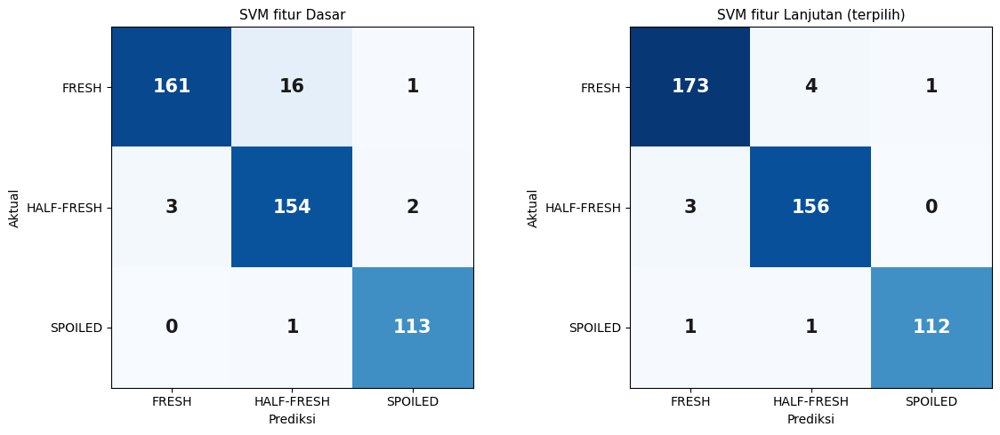

In [ ]:
# Latih model akhir (dengan probabilitas) memakai parameter terbaik tiap set fitur, pada seluruh data train
final_models = {}
for s in SETS:
    b = best[s]
    final_models[s] = make_pipeline(b["C"], b["gamma_x"] / Xtr[s].shape[1], probability=True).fit(Xtr[s], ytr)

# Model terpilih = skor CV (rata-rata gambar asli + gambar berubah) tertinggi. Data test tidak dipakai untuk memilih.
chosen = max(best, key=lambda s: best[s]["skor"])
print("Fitur terpilih berdasarkan cross-validation:", chosen)

clean = (tte == "asli")
def draw_cm(ax, cm, title):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.sum(axis=1).max())
    ax.set_title(title, fontsize=11); ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(CLASS_NAMES); ax.set_yticklabels(CLASS_NAMES)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=15, fontweight="bold",
                    color="white" if cm[i, j] > cm.sum(axis=1).max() / 2 else "#1a1a1a")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, s in zip(axes, SETS):
    pred = final_models[s].predict(Xte[s][clean])
    print("=" * 60); print(f"SVM fitur {s}" + ("  <== TERPILIH" if s == chosen else ""), "| akurasi test:", f"{accuracy_score(yte[clean], pred)*100:.2f}%")
    print(classification_report(yte[clean], pred, target_names=CLASS_NAMES, digits=4))
    draw_cm(ax, confusion_matrix(yte[clean], pred, labels=[0, 1, 2]), f"SVM fitur {s}" + (" (terpilih)" if s == chosen else ""))
plt.tight_layout(); plt.show()

## 17. Uji ketahanan terhadap perubahan cahaya

Setiap gambar test dievaluasi dalam lima kondisi: **asli**, **terang** (×1.35), **gelap** (×0.65), **hangat** (lebih merah/kuning), dan **dingin** (lebih biru). Tabel dan grafik membandingkan akurasi kedua model di tiap kondisi.

Ini mendekati situasi foto lapangan. Model yang akurasinya jatuh jauh pada kondisi tertentu, misalnya "dingin", kemungkinan akan bermasalah di foto yang diambil dengan lampu berwarna. Baris **rata-rata** merangkum ketahanan keseluruhan.

,SVM Dasar,SVM Lanjutan
kondisi cahaya,,
asli,94.90,97.78
terang,77.83,94.01
gelap,78.49,90.47
hangat,73.17,60.98
dingin,67.85,79.16
rata-rata,78.45,84.48


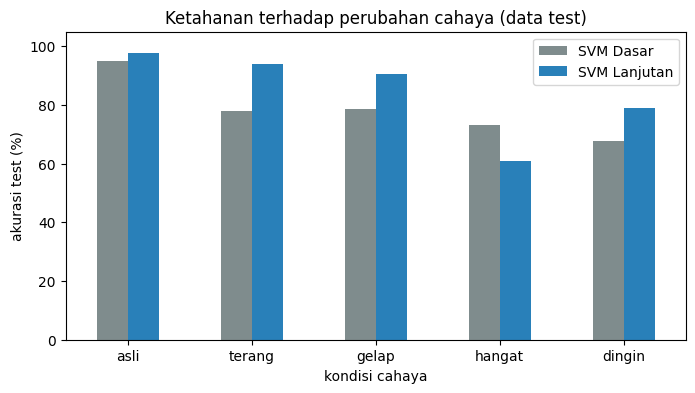

In [ ]:
rows = []
for cond in ["asli"] + SHIFT_NAMES:
    idx = (tte == cond)
    row = {"kondisi cahaya": cond}
    for s in SETS:
        row[f"SVM {s}"] = accuracy_score(yte[idx], final_models[s].predict(Xte[s][idx])) * 100
    rows.append(row)
rob = pd.DataFrame(rows).set_index("kondisi cahaya")
rob.loc["rata-rata"] = rob.mean()
display(rob.round(2))

rob.drop(index="rata-rata").plot(kind="bar", figsize=(8, 4), color=["#7f8c8d", "#2980b9"])
plt.ylabel("akurasi test (%)"); plt.ylim(0, 105); plt.xticks(rotation=0)
plt.title("Ketahanan terhadap perubahan cahaya (data test)")
plt.show()

## 18. Uji pada foto lapangan (di luar dataset)

Upload satu atau beberapa foto daging dari luar dataset. Setiap foto diproses dengan tahapan yang sama dengan data test: orientasi diperbaiki, foto besar diperkecil (sisi terpanjang 416 px), di-resize 224×224, dinormalisasi 0–1, tanpa augmentasi, lalu disegmentasi. Hasil yang ditampilkan: foto, hasil segmentasi, dan probabilitas dari kedua model.

Ini uji yang paling penting. Akurasi pada data test belum menjamin model bagus pada foto sungguhan. Periksa juga apakah hasil segmentasinya masuk akal, karena jika mask-nya salah, fitur ikut salah.

Saving WhatsApp Image 2026-11-04 at 18.42.44 1.jpeg to WhatsApp Image 2026-11-04 at 18.42.44 1 (1).jpeg


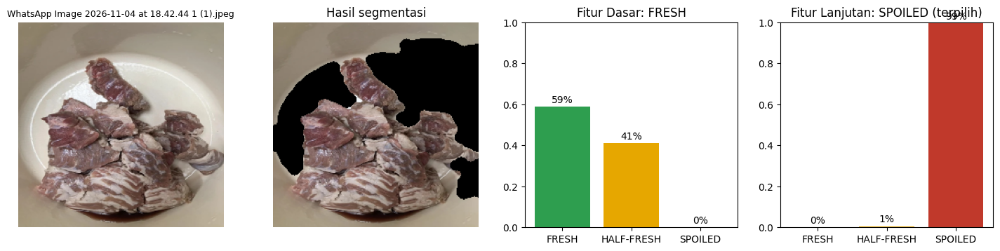

In [ ]:
from PIL import Image, ImageOps
from google.colab import files

def load_photo_u8(path, max_side=416):
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")    # benahi orientasi foto HP
    im.thumbnail((max_side, max_side), Image.LANCZOS)                # perkecil foto yang terlalu besar
    return cv2.resize(cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR), IMG_SIZE)   # 224 x 224

def test_photos(paths):
    for p in paths:
        img = load_photo_u8(p)
        img01 = normalize01(img); mask, fb = segment_meat(img01)
        fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
        ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0].set_title(os.path.basename(p), fontsize=9)
        ax[1].imshow(cv2.cvtColor(apply_mask(img, mask), cv2.COLOR_BGR2RGB))
        ax[1].set_title("Hasil segmentasi" + (" (gagal)" if fb else ""))
        for a in ax[:2]: a.axis("off")
        for a, s in zip(ax[2:], SETS):
            feat = SETS[s](img01, mask).reshape(1, -1)
            proba = final_models[s].predict_proba(feat)[0]; pred = int(final_models[s].predict(feat)[0])
            a.bar(CLASS_NAMES, proba, color=CLASS_COLORS); a.set_ylim(0, 1)
            a.set_title(f"Fitur {s}: {CLASS_NAMES[pred]}" + (" (terpilih)" if s == chosen else ""))
            for i, v in enumerate(proba): a.text(i, v + 0.02, f"{v*100:.0f}%", ha="center")
        plt.show()

up = files.upload()
test_photos(sorted(up.keys()))

## 19. Menyimpan model

Kedua model disimpan dalam format `.pkl`, beserta `svm_config_v3.json` yang mencatat seluruh parameter preprocessing, augmentasi, segmentasi, tata letak fitur, dan parameter SVM terbaik. Catatan ini diperlukan jika model nanti dipindah ke aplikasi, karena parameter yang sama harus dipakai di sana. File **tidak diunduh otomatis**. Ambil lewat panel file di sisi kiri Colab (klik kanan → Download).

In [ ]:
for s in SETS:
    joblib.dump(final_models[s], f"svm_meat_fitur_{s.lower()}.pkl")

config = {
    "img_size": list(IMG_SIZE), "normalize": "pixel / 255 (rentang 0-1)",
    "augmentation": {**AUG, "brightness": list(AUG["brightness"]), "gamma": list(AUG["gamma"]), "n_copies_per_train_image": N_AUG},
    "segmentation": {"s_min": S_MIN, "v_min": V_MIN, "hue_max_low_deg": HUE_MAX_LOW, "hue_min_high_deg": HUE_MIN_HIGH,
                     "min_cover": MIN_COVER, "blur": K_BLUR, "close": K_CLOSE, "open": K_OPEN},
    "feature_set_chosen": chosen, "feature_dims": dims, "feature_layout_lanjutan": B_LAYOUT,
    "svm": {s: {"kernel": "rbf", "C": float(best[s]["C"]), "gamma": float(best[s]["gamma_x"] / dims[s]),
                "class_weight": "balanced", "cv_score": float(best[s]["skor"])} for s in SETS},
    "seed": SEED, "class_order": CLASS_NAMES,
}
json.dump(config, open("svm_config_v3.json", "w"), indent=2)
print("Tersimpan di panel file Colab:", [f for f in os.listdir(".") if f.startswith("svm_")])

Tersimpan di panel file Colab: ['svm_config_v3.json', 'svm_meat_fitur_lanjutan.pkl', 'svm_meat_fitur_dasar.pkl']
